<h1> Import cell

In [1]:
import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor, GradientBoostingRegressor, ExtraTreesRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
#from xgboost import XGBRegressor
from prettytable import PrettyTable
from utils import plot_apartment_choropleth, compare_distributions, compare_categorical_distributions, correlation_matrix, compare_scatter_outliers, plot_square_feet_comparison
import preprocessing
importlib.reload(preprocessing)
from preprocessing import preprocessing_dev, preprocessing_eval
import importlib
from sklearn.preprocessing import StandardScaler
from catboost import CatBoostRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVR

<h1> Datasets loading

In [2]:
df = pd.read_csv("development.csv", header="infer")
evaluate_df = pd.read_csv("evaluation.csv", header="infer")

<h1> Data exploration

<h3> Data type identification for both datasets

In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 79589 entries, 0 to 79588
Data columns (total 21 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   category      79589 non-null  object 
 1   title         79589 non-null  object 
 2   body          79589 non-null  object 
 3   amenities     66785 non-null  object 
 4   bathrooms     79538 non-null  float64
 5   bedrooms      79500 non-null  float64
 6   currency      79589 non-null  object 
 7   fee           79589 non-null  object 
 8   has_photo     79589 non-null  object 
 9   pets_allowed  31269 non-null  object 
 10  price         79589 non-null  float64
 11  price_type    79589 non-null  object 
 12  square_feet   79589 non-null  int64  
 13  address       6363 non-null   object 
 14  cityname      79355 non-null  object 
 15  state         79355 non-null  object 
 16  latitude      79566 non-null  float64
 17  longitude     79566 non-null  float64
 18  source        79589 non-nu

In [4]:
print(evaluate_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19898 entries, 0 to 19897
Data columns (total 20 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   category      19898 non-null  object 
 1   title         19898 non-null  object 
 2   body          19898 non-null  object 
 3   amenities     16658 non-null  object 
 4   bathrooms     19887 non-null  float64
 5   bedrooms      19864 non-null  float64
 6   currency      19898 non-null  object 
 7   fee           19898 non-null  object 
 8   has_photo     19898 non-null  object 
 9   pets_allowed  7796 non-null   object 
 10  price_type    19898 non-null  object 
 11  square_feet   19898 non-null  int64  
 12  address       1578 non-null   object 
 13  cityname      19830 non-null  object 
 14  state         19830 non-null  object 
 15  latitude      19896 non-null  float64
 16  longitude     19896 non-null  float64
 17  source        19898 non-null  object 
 18  time          19898 non-nu

<h3> Shapes of both the development and the evaluation dataset

In [5]:
print(df.shape)
print(evaluate_df.shape)

(79589, 21)
(19898, 20)


<h1> Exploration plots

<h3> Geographical distribution of apartments in both development and evaluation datasets

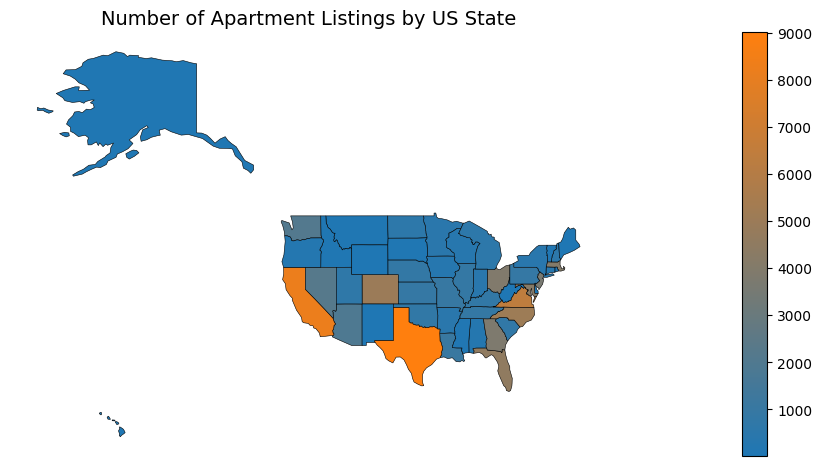

In [9]:
plot_apartment_choropleth(df)

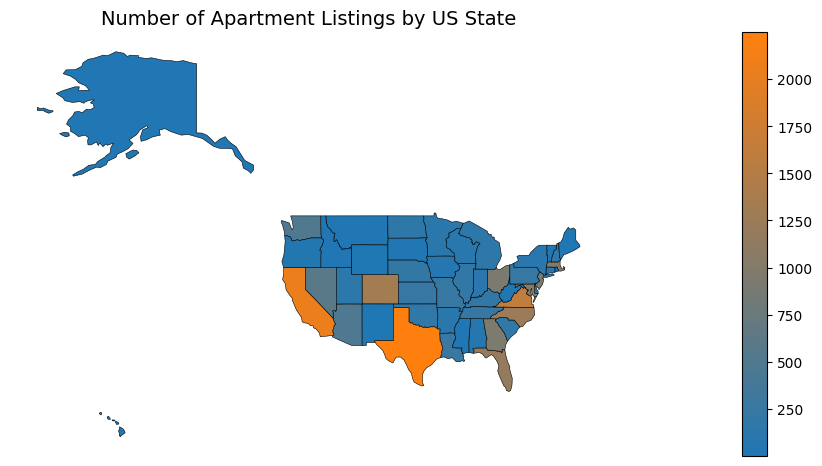

In [10]:
plot_apartment_choropleth(evaluate_df)

<h3> Comparison of normalized frequency distributions of numerical features in both datasets

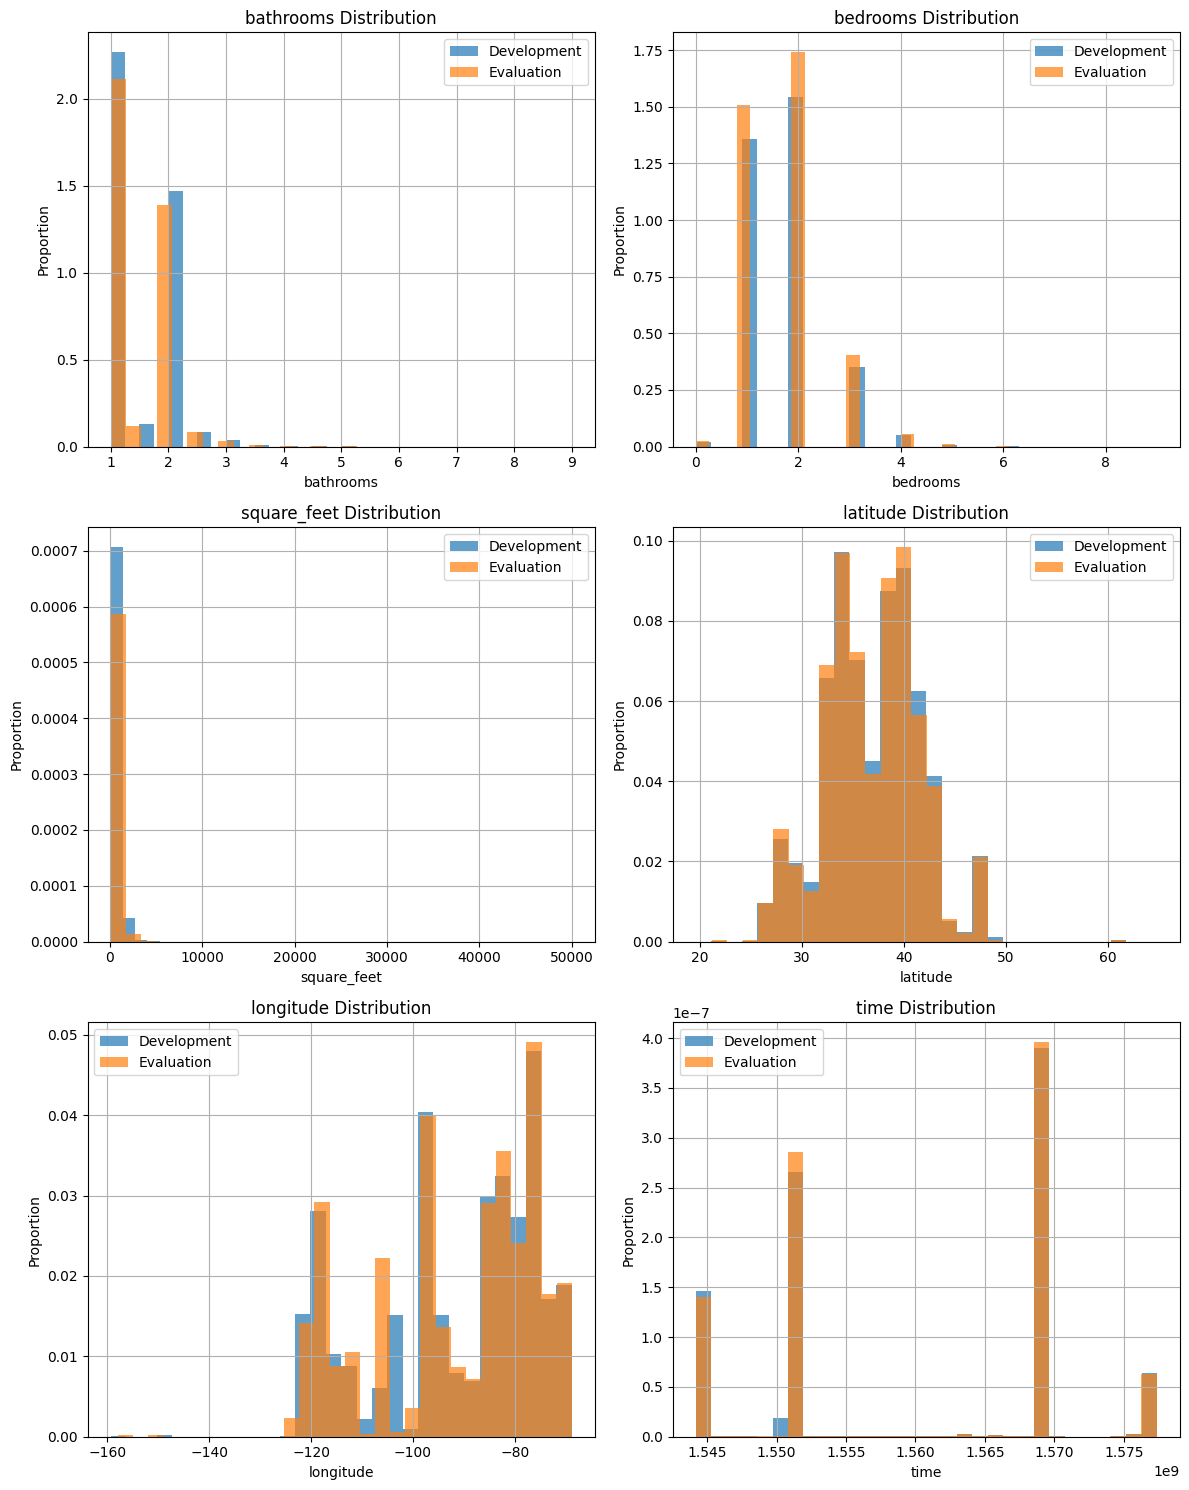

In [4]:
df_plot = df.drop(columns=["price"])
compare_distributions(df_plot, evaluate_df)

<h3> Comparison of normalized frequency distributions of categorical features in both datasets

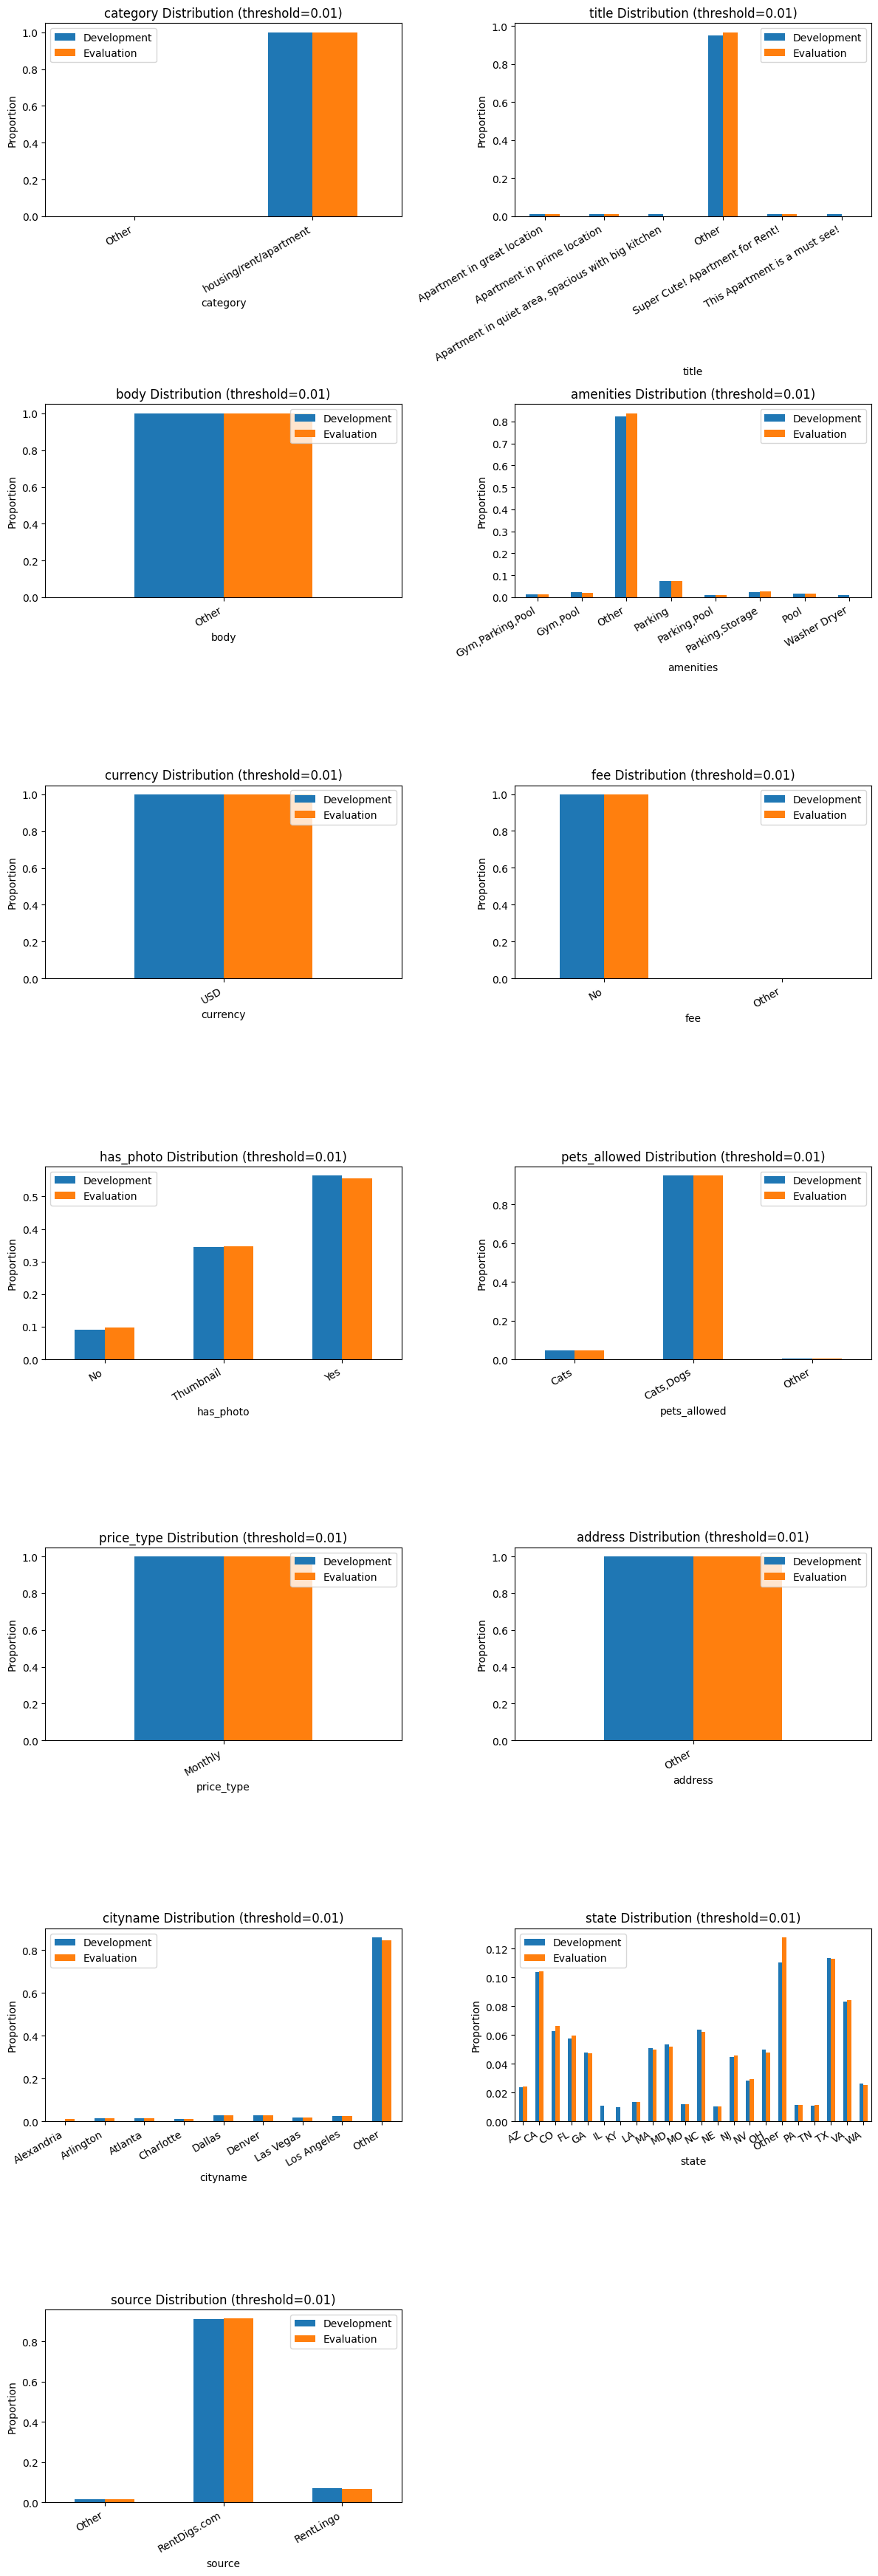

In [5]:
compare_categorical_distributions(df, evaluate_df)

<h3> Correlation matrix heatmap

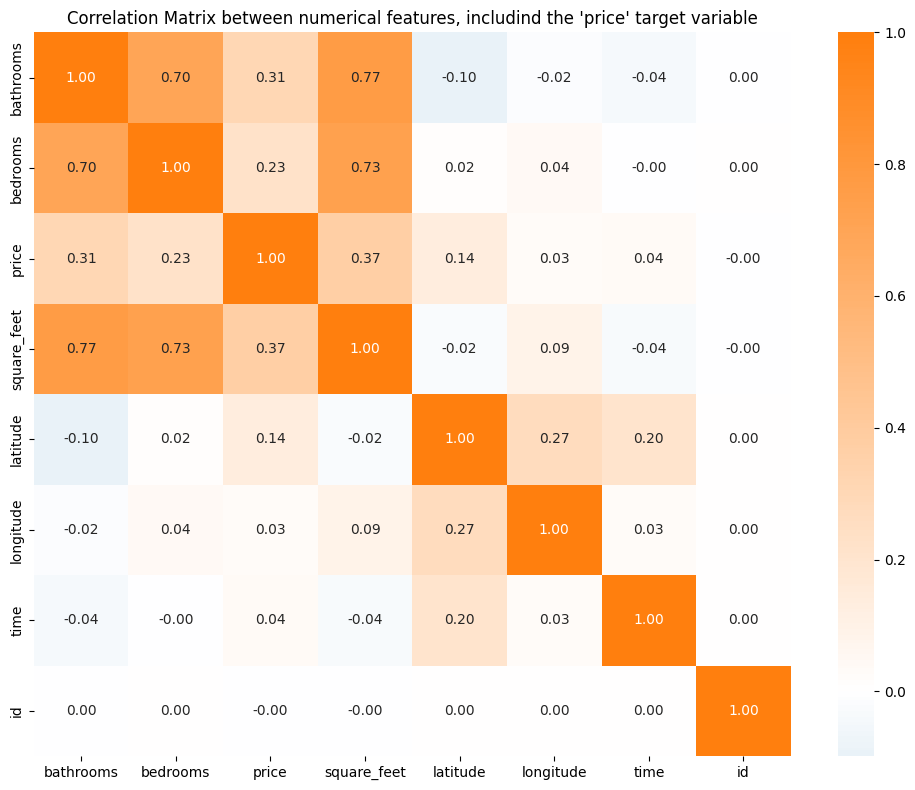

In [3]:
correlation_matrix(df)

<h1> Missing values exploration

<h3> Number of missing values per feature in the development dataset

In [6]:
missing_per_feature = df.isnull().sum()
print(missing_per_feature)

category            0
title               0
body                0
amenities       12804
bathrooms          51
bedrooms           89
currency            0
fee                 0
has_photo           0
pets_allowed    48320
price               0
price_type          0
square_feet         0
address         73226
cityname          234
state             234
latitude           23
longitude          23
source              0
time                0
id                  0
dtype: int64


<h3> Number of missing values per feature in the evaluation dataset

In [7]:
missing_per_feature = evaluate_df.isnull().sum()
print(missing_per_feature)

category            0
title               0
body                0
amenities        3240
bathrooms          11
bedrooms           34
currency            0
fee                 0
has_photo           0
pets_allowed    12102
price_type          0
square_feet         0
address         18320
cityname           68
state              68
latitude            2
longitude           2
source              0
time                0
id                  0
dtype: int64


<h3> Focus on geographical features: latitude, longitude, cityname and state

In [8]:
# Combining datasets
df_to = pd.concat([df, evaluate_df], ignore_index=True)

# Boolean masks creation
lat_lon_missing = df['latitude'].isna() & df['longitude'].isna()
city_state_missing = df['cityname'].isna() & df['state'].isna()
lat_lon_present = df['latitude'].notna() & df['longitude'].notna()
city_state_present = df['cityname'].notna() & df['state'].notna()

# 1. All missing: latitude, longitude, cityname e state
all_missing = lat_lon_missing & city_state_missing
print("1. latitude, longitude, cityname and state missing:", all_missing.sum())

# 2. latitude and longitude missing, cityname and state present
geo_missing_city_present = lat_lon_missing & city_state_present
print("2. latitude and longitude missing, cityname and state present:", geo_missing_city_present.sum())

# 3. cityname and state missing, latitude and longitude present
city_missing_geo_present = city_state_missing & lat_lon_present
print("3. cityname and state missing, latitude and longitude present:", city_missing_geo_present.sum())

# 4. Only cityname and state missing
print("4. cityname and state missing:", city_state_missing.sum())

# 5. Only lat/lon missing
print("5. latitude and longitude missing:", lat_lon_missing.sum())

1. latitude, longitude, cityname and state missing: 23
2. latitude and longitude missing, cityname and state present: 0
3. cityname and state missing, latitude and longitude present: 211
4. cityname and state missing: 234
5. latitude and longitude missing: 23


<h3> Looking for geographical information in the 'title' and 'body' fiels

In [9]:
# Filtrering rows with missing latitude or longitude
missing_geo = evaluate_df[evaluate_df['latitude'].isnull() | evaluate_df['longitude'].isnull()]

# Printing 'title' and 'body' for each row with missing latitude or longitude
for idx, row in missing_geo.iterrows():
    print(f"Index: {idx}")
    print("\nTitle:")
    print(row['title'])

    print("\nBody:")
    print(row['body'])

    print("-"*50)

Index: 5066

Title:
Spacious Three BR, Two BA

Body:
Shores, you will enjoy an unrivaled lifestyle within the tranquil setting of the Chesapeake Bay with all the conveniences of Virginia Beach Town Center and the Oceanfront. We are minutes away from highly desirable schools, award-winning restaurants, shopping, s, entertainment and fabulous nightlife. Shores also provides residents the convenience of being situated adjacent to many businesses and restaurants. Unwind in a NEWLY REMODELED apartment home designed to include lavish interiors and rich amenities that provide a lifestyle you merely dreamed of. These stunning apartment homes range from expansive one, 2 and 3 beds units. At Shores you will benefit from the max in comfort and convenience. Located 1 block from the beach our Virginia Beach rentals are steps from the for all the summertime fun you can enjoy. More units available: three Bd / 2 Bedrooms 1,316 square ft for $1,705/mo | one Bd / 2 Bedrooms 1,078 sq. feet for $1,554/mo 

<h1> Outliers detection

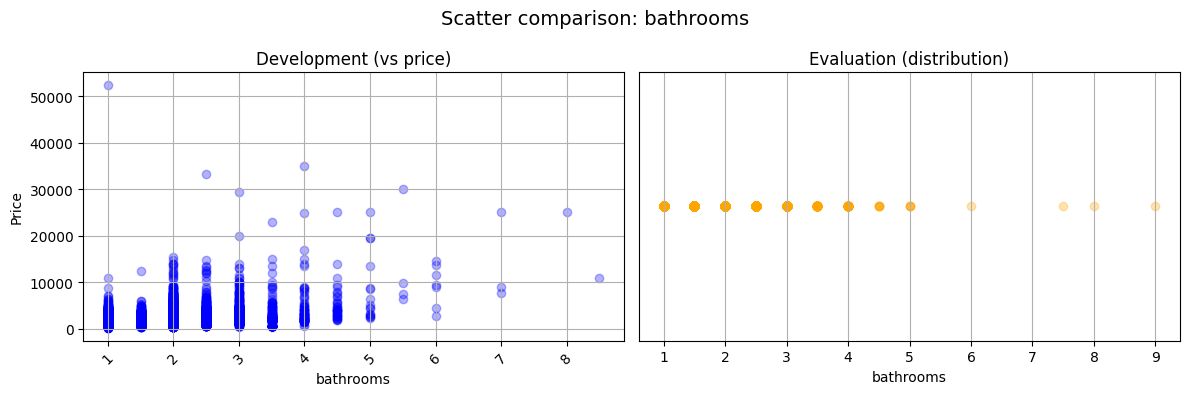

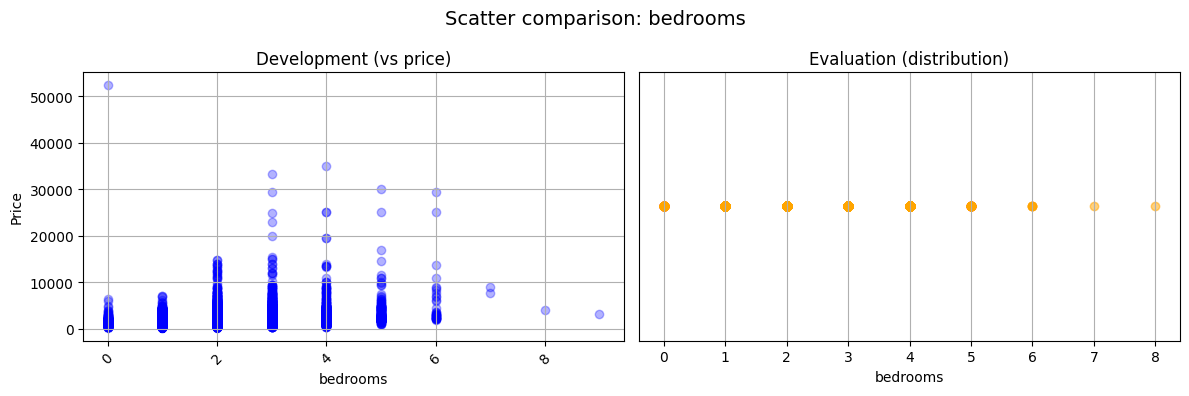

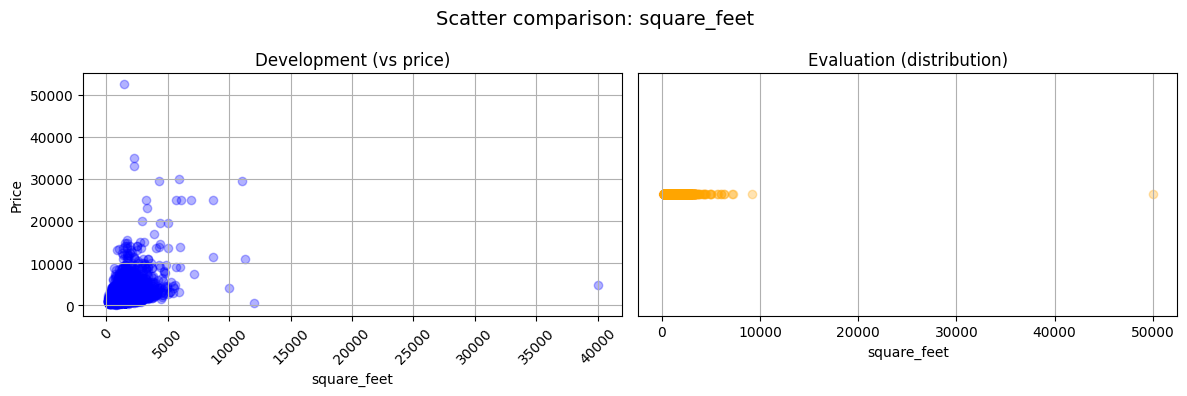

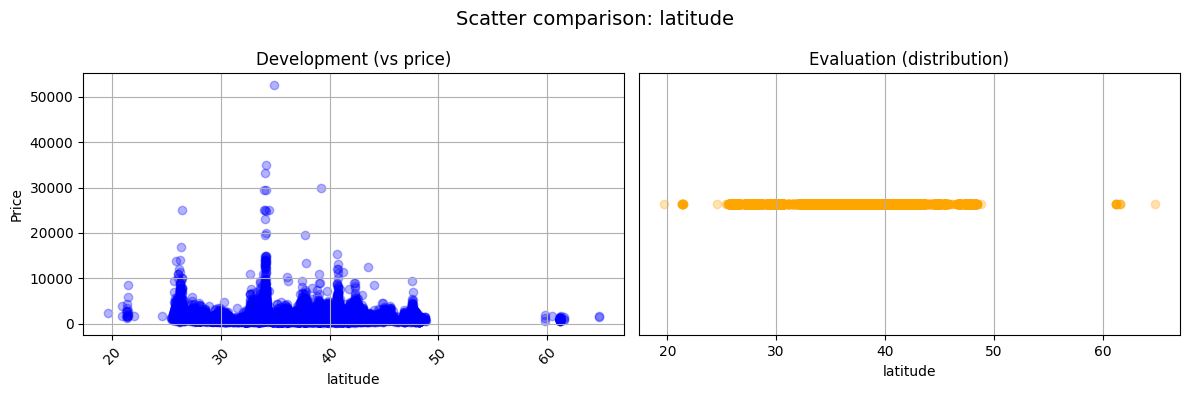

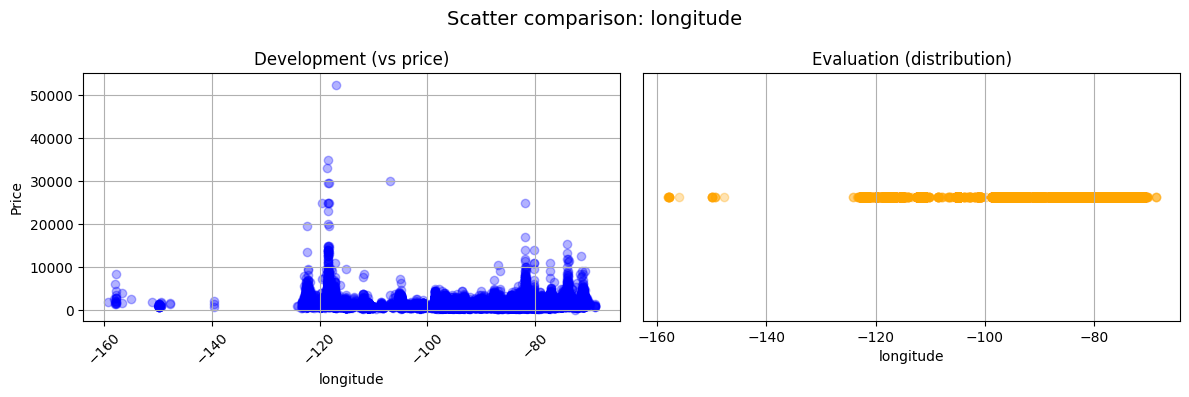

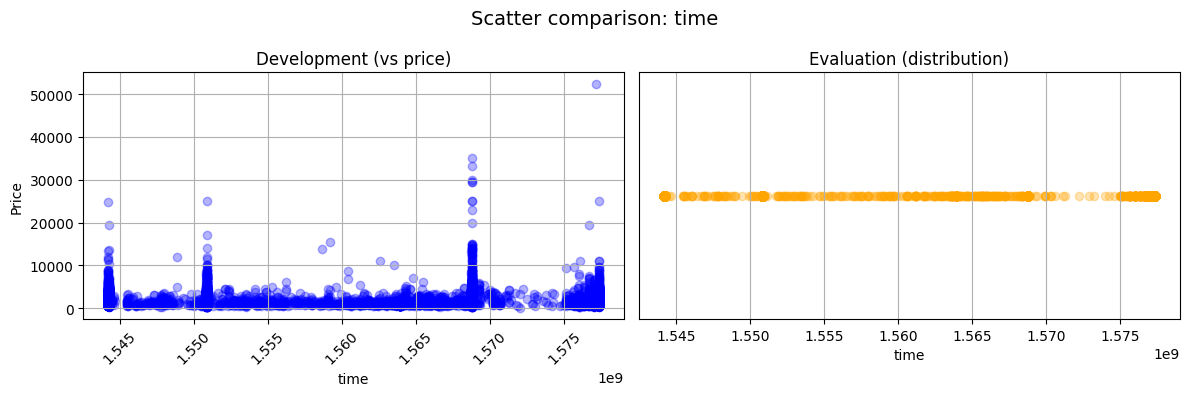

In [6]:
compare_scatter_outliers(df, evaluate_df)

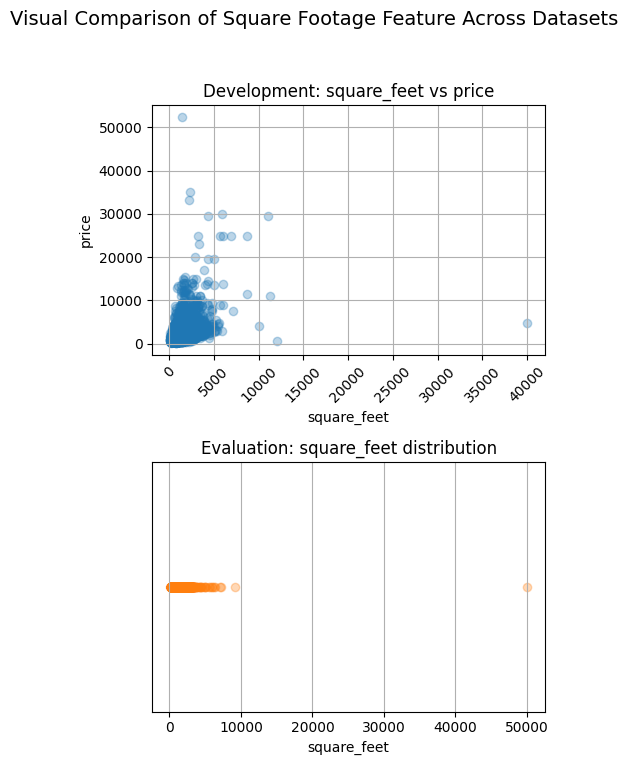

In [3]:
plot_square_feet_comparison(df, evaluate_df)

<h1> Preprocessing

In [3]:
df = preprocessing_dev(df)
evaluate_df = preprocessing_eval(df,evaluate_df)
y = df["price"]
df.drop(columns=["price","square_feet_quantile"], inplace=True)
evaluate_df.drop(columns = "square_feet_quantile", inplace = True)

square feet quantile: 0        5
1        2
2        1
3        4
4        4
        ..
79584    9
79585    8
79586    0
79587    0
79588    0
Name: square_feet_quantile, Length: 79566, dtype: int64
Imputato 5066: 40.6331889, 17.9414995, None, None
Imputato 8541: 37.7693792, -121.5445066, None, None


RateLimiter caught an error, retrying (0/2 tries). Called with (*((39.8163, -98.5576),), **{'exactly_one': True}).
Traceback (most recent call last):
  File "/Users/giulianaparadiso/Desktop/PoliTo/Data science lab/Progetto/.venv/lib/python3.13/site-packages/geopy/adapters.py", line 298, in get_text
    page = self.urlopen(req, timeout=timeout)
  File "/opt/homebrew/Cellar/python@3.13/3.13.4/Frameworks/Python.framework/Versions/3.13/lib/python3.13/urllib/request.py", line 489, in open
    response = self._open(req, data)
  File "/opt/homebrew/Cellar/python@3.13/3.13.4/Frameworks/Python.framework/Versions/3.13/lib/python3.13/urllib/request.py", line 506, in _open
    result = self._call_chain(self.handle_open, protocol, protocol +
                              '_open', req)
  File "/opt/homebrew/Cellar/python@3.13/3.13.4/Frameworks/Python.framework/Versions/3.13/lib/python3.13/urllib/request.py", line 466, in _call_chain
    result = func(*args)
  File "/opt/homebrew/Cellar/python@3.13/3

<h3> Checking if there are remaining missing features

In [4]:
missing_per_feature = df.isnull().sum()
print(missing_per_feature)

bathrooms             0
bedrooms              0
square_feet           0
latitude              0
longitude             0
time                  0
id                    0
max_from_body         0
min_from_body         0
std_from_body         0
mean_from_body        0
max_from_title        0
min_from_title        0
std_from_title        0
mean_from_title       0
AC                    0
Alarm                 0
Basketball            0
Cable or Satellite    0
Clubhouse             0
Dishwasher            0
Doorman               0
Elevator              0
Fireplace             0
Garbage Disposal      0
Gated                 0
Golf                  0
Gym                   0
Hot Tub               0
Internet Access       0
Luxury                0
Parking               0
Patio/Deck            0
Playground            0
Pool                  0
Refrigerator          0
Storage               0
TV                    0
Tennis                0
View                  0
Washer Dryer          0
Wood Floors     

In [5]:
missing_per_feature = evaluate_df.isnull().sum()
print(missing_per_feature)

bathrooms             0
bedrooms              0
square_feet           0
latitude              0
longitude             0
time                  0
id                    0
max_from_body         0
min_from_body         0
std_from_body         0
mean_from_body        0
max_from_title        0
min_from_title        0
std_from_title        0
mean_from_title       0
AC                    0
Alarm                 0
Basketball            0
Cable or Satellite    0
Clubhouse             0
Dishwasher            0
Doorman               0
Elevator              0
Fireplace             0
Garbage Disposal      0
Gated                 0
Golf                  0
Gym                   0
Hot Tub               0
Internet Access       0
Luxury                0
Parking               0
Patio/Deck            0
Playground            0
Pool                  0
Refrigerator          0
Storage               0
TV                    0
Tennis                0
View                  0
Washer Dryer          0
Wood Floors     

<h3> Checking shapes

In [6]:
df.shape, y.shape

((79566, 43), (79566,))

In [7]:
evaluate_df.shape

(19898, 43)

In [4]:
for col in evaluate_df.columns:
    if col not in df.columns:
        evaluate_df.drop(columns=col, inplace=True)

<h3> Checking if the column names in the two datasets are identical

In [5]:
evaluate_df.columns == df.columns

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True])

<h1> Training

<h3> Splitting the dataset

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(df, y, test_size=0.2, shuffle=True, random_state=42)

<h3> Applying standardization

In [11]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

<h2> Comparison between standardized and non-standardized data

<h3> Comparison between model performances with default hyperparameters - non standardized data

In [ ]:
table = PrettyTable()
table.field_names = ["Model", "MAE"]

# Random Forest
rfr = RandomForestRegressor(n_jobs=-1)
rfr.fit(X_train, y_train)
y_pred = rfr.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
table.add_row(["Random Forest", mae])

# Extra Trees
extra_tree = ExtraTreesRegressor(n_estimators=500, n_jobs=-1, max_features=0.5)
extra_tree.fit(X_train, y_train)
y_pred_ext = extra_tree.predict(X_test)
mae = mean_absolute_error(y_test, y_pred_ext)
table.add_row(["Extra Trees", mae])

# XGBoost 
xgb = XGBRegressor(learning_rate=0.05, n_estimators=500, max_depth=6, reg_alpha=1, reg_lambda=5)
xgb.fit(X_train, np.log1p(y_train))
y_pred_xgb = xgb.predict(X_test)
mae = mean_absolute_error(y_test, np.expm1(y_pred_xgb))
table.add_row(["XGBoost", mae])

# HistGradientBoost 
hgb = HistGradientBoostingRegressor(max_iter=1000, learning_rate=0.05, max_depth=6)
hgb.fit(X_train, y_train)
y_preds_hgb = hgb.predict(X_test)
mae = mean_absolute_error(y_test, y_preds_hgb)
table.add_row(["HistGradientBoost", mae])

# CatBoost 
catboost = CatBoostRegressor(iterations=500, learning_rate=0.05, depth=6, verbose=0)
catboost.fit(X_train, y_train)
y_pred_catboost = catboost.predict(X_test)
mae = mean_absolute_error(y_test, y_pred_catboost)
table.add_row(["CatBoost", mae])

# Gradient Boosting
GB = GradientBoostingRegressor()
GB.fit(X_train, y_train)
y_pred_GB = GB.predict(X_test)
mae = mean_absolute_error(y_test, y_pred_GB)
table.add_row(["Gradient Boost", mae])

# SVR 
svr = SVR()
svr.fit(X_train_scaled, y_train)
y_pred_svr = svr.predict(X_test_scaled)
mae = mean_absolute_error(y_test, y_pred_svr)
table.add_row(["SVR", mae])

# MLP 
model_MLP = MLPRegressor(
    hidden_layer_sizes=(100, 50),
    alpha=0.001,
    learning_rate_init=0.001,
    max_iter=1000,
    early_stopping=False,
    random_state=42
)
model_MLP.fit(X_train_scaled, y_train)
y_pred_MLP = model_MLP.predict(X_test_scaled)
mae = mean_absolute_error(y_test, y_pred_MLP)
table.add_row(["MLP", mae])

print(table.get_string(sortby="MAE"))

<h3> Comparison between model performances with default hyperparameters - standardized data

In [ ]:
table = PrettyTable()
table.field_names = ["Model", "MAE"]

# Random Forest
rfr = RandomForestRegressor(n_jobs=-1)
rfr.fit(X_train_scaled, y_train)
y_pred = rfr.predict(X_test_scaled)
mae = mean_absolute_error(y_test, y_pred)
table.add_row(["Random Forest", mae])

# Extra Trees
extra_tree = ExtraTreesRegressor(n_estimators=500, n_jobs=-1, max_features=0.5)
extra_tree.fit(X_train_scaled, y_train)
y_pred_ext = extra_tree.predict(X_test_scaled)
mae = mean_absolute_error(y_test, y_pred_ext)
table.add_row(["Extra Trees", mae])

# XGBoost 
xgb = XGBRegressor(learning_rate=0.05, n_estimators=500, max_depth=6, reg_alpha=1, reg_lambda=5)
xgb.fit(X_train_scaled, np.log1p(y_train))
y_pred_xgb = xgb.predict(X_test_scaled)
mae = mean_absolute_error(y_test, np.expm1(y_pred_xgb))
table.add_row(["XGBoost", mae])

# HistGradientBoost 
hgb = HistGradientBoostingRegressor(max_iter=1000, learning_rate=0.05, max_depth=6)
hgb.fit(X_train_scaled, y_train)
y_preds_hgb = hgb.predict(X_test_scaled)
mae = mean_absolute_error(y_test, y_preds_hgb)
table.add_row(["HistGradientBoost", mae])

# CatBoost 
catboost = CatBoostRegressor(iterations=500, learning_rate=0.05, depth=6, verbose=0)
catboost.fit(X_train_scaled, y_train)
y_pred_catboost = catboost.predict(X_test_scaled)
mae = mean_absolute_error(y_test, y_pred_catboost)
table.add_row(["CatBoost", mae])

# Gradient Boosting
GB = GradientBoostingRegressor()
GB.fit(X_train_scaled, y_train)
y_pred_GB = GB.predict(X_test_scaled)
mae = mean_absolute_error(y_test, y_pred_GB)
table.add_row(["Gradient Boost", mae])

# SVR 
svr = SVR()
svr.fit(X_train_scaled, y_train)
y_pred_svr = svr.predict(X_test_scaled)
mae = mean_absolute_error(y_test, y_pred_svr)
table.add_row(["SVR", mae])

# MLP 
model_MLP = MLPRegressor(
    hidden_layer_sizes=(100, 50),
    alpha=0.001,
    learning_rate_init=0.001,
    max_iter=1000,
    early_stopping=False,
    random_state=42
)
model_MLP.fit(X_train_scaled, y_train)
y_pred_MLP = model_MLP.predict(X_test_scaled)
mae = mean_absolute_error(y_test, y_pred_MLP)
table.add_row(["MLP", mae])

print(table.get_string(sortby="MAE"))

<h3> Grid search for hyperparameters tuning

In [ ]:
param_grid = {
    'n_estimators': [100, 300, 500],
    'max_depth': [None, 10, 20],
}
extra_tree = ExtraTreesRegressor()
grid_et = GridSearchCV(extra_tree, param_grid, cv=5, n_jobs=-1, scoring='neg_mean_absolute_error')
grid_et.fit(X_train, y_train)

rfr = RandomForestRegressor()
grid_rf = GridSearchCV(rfr, param_grid, cv=5, n_jobs=-1, scoring='neg_mean_absolute_error')
grid_rf.fit(X_train, y_train)

param_grid = {
    'n_estimators': [100, 300],
    'max_depth': [None, 3, 5],
    'learning_rate': [0.05, 0.1],
    'gamma': [0, 0.1]
}
xgb = XGBRegressor()
grid_xgb = GridSearchCV(xgb, param_grid, cv=5, n_jobs=-1, scoring='neg_mean_absolute_error')
grid_xgb.fit(X_train, y_train)


param_grid = {
    'learning_rate': [0.05, 0.1],
    'max_iter': [100, 200, 500],
    'max_leaf_nodes': [31, 63],
}
hgb = HistGradientBoostingRegressor()
grid_hgb = GridSearchCV(hgb, param_grid, cv=5, n_jobs=-1, scoring='neg_mean_absolute_error')
grid_hgb.fit(X_train, y_train)

param_grid = {
    'iterations': [100, 300],
    'depth': [4, 6],
    'learning_rate': [0.05, 0.1],
    'l2_leaf_reg': [3, 5]
}
catboost = CatBoostRegressor(verbose=0)
grid_cb = GridSearchCV(catboost, param_grid, cv=3, n_jobs=-1, scoring='neg_mean_absolute_error')
grid_cb.fit(X_train, y_train)

param_grid = {
    'n_estimators': [100, 300],
    'learning_rate': [0.05, 0.1],
    'max_depth': [3, 5],
    'min_samples_leaf': [1, 2] 
}
GB = GradientBoostingRegressor()
grid_gb = GridSearchCV(GB, param_grid, cv=5, n_jobs=-1, scoring='neg_mean_absolute_error')
grid_gb.fit(X_train, y_train)

<h3> Table with hyperparametrs best configuration and MAE for each model

In [ ]:
# Prepare PrettyTable
table = PrettyTable()
table.field_names = ["Model", "Best Params", "MAE (Test)"]

# ExtraTrees
best_et_model = grid_et.best_estimator_
y_pred_et = best_et_model.predict(X_test)
mae_et = mean_absolute_error(y_test, y_pred_et)
table.add_row(["ExtraTrees", grid_et.best_params_, mae_et])

# RandomForest
best_rf_model = grid_rf.best_estimator_
y_pred_rf = best_rf_model.predict(X_test)
mae_rf = mean_absolute_error(y_test, y_pred_rf)
table.add_row(["RandomForest", grid_rf.best_params_, mae_rf])

# XGBoost
best_xgb_model = grid_xgb.best_estimator_
y_pred_xgb = best_xgb_model.predict(X_test)
mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
table.add_row(["XGBoost", grid_xgb.best_params_, mae_xgb])

# HistGradientBoosting
best_hgb_model = grid_hgb.best_estimator_
y_pred_hgb = best_hgb_model.predict(X_test)
mae_hgb = mean_absolute_error(y_test, y_pred_hgb)
table.add_row(["HistGradientBoosting", grid_hgb.best_params_, mae_hgb])

# CatBoost
best_cb_model = grid_cb.best_estimator_
y_pred_cb = best_cb_model.predict(X_test)
mae_cb = mean_absolute_error(y_test, y_pred_cb)
table.add_row(["CatBoost", grid_cb.best_params_, mae_cb])

# GradientBoosting
best_gb_model = grid_gb.best_estimator_
y_pred_gb = best_gb_model.predict(X_test)
mae_gb = mean_absolute_error(y_test, y_pred_gb)
table.add_row(["GradientBoosting", grid_gb.best_params_, mae_gb])

# Print sorted by MAE
print(table.get_string(sortby="MAE (Test)"))

<h1> Evaluation

In [ ]:
rfr_online = RandomForestRegressor(n_jobs=-1)
rfr_online.fit(df, y)
y_pred = rfr_online.predict(evaluate_df)
results_df = pd.DataFrame({
    "Id": evaluate_df["id"],
    "Predicted": y_pred.astype(float)  
})

results_df.to_csv("predictions.csv", index=False)

<h3> Feature importances for Random Forest Regressor

In [ ]:
importances = rfr.feature_importances_
importances = 100 * importances / importances.sum()
feature_names = X_train.columns
feat_imp = (pd.Series(importances, index=feature_names).sort_values(ascending=False).round(2))
print(feat_imp.head(20))

In [6]:
extra_tree = ExtraTreesRegressor(n_estimators=500, n_jobs=-1)
extra_tree.fit(df, y)
y_pred = extra_tree.predict(evaluate_df)
results_df = pd.DataFrame({
    "Id": evaluate_df["id"],
    "Predicted": y_pred.astype(float)
})

results_df.to_csv("predictions.csv", index=False)

<h3> Feature importances for Extra Tree Regressor

In [ ]:
importances = extra_tree.feature_importances_
importances = 100 * importances / importances.sum()
feature_names = df.columns
feat_imp = (pd.Series(importances, index=feature_names).sort_values(ascending=False).round(2))
print(feat_imp.head(20))

longitude          23.91
latitude           11.98
square_feet        11.37
bathrooms          10.70
time                5.40
min_from_body       4.03
mean_from_body      3.42
max_from_body       2.51
bedrooms            2.42
id                  1.70
Gym                 1.38
std_from_body       1.25
Pool                1.25
Elevator            1.25
Parking             1.17
mean_from_title     1.07
max_from_title      1.02
min_from_title      1.01
Playground          0.98
Patio/Deck          0.97
dtype: float64
